Split sizes -> train=600, val=200, test=200


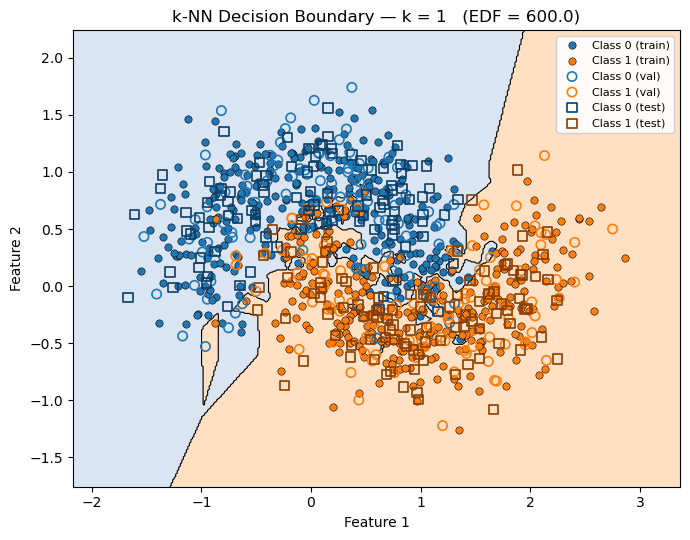

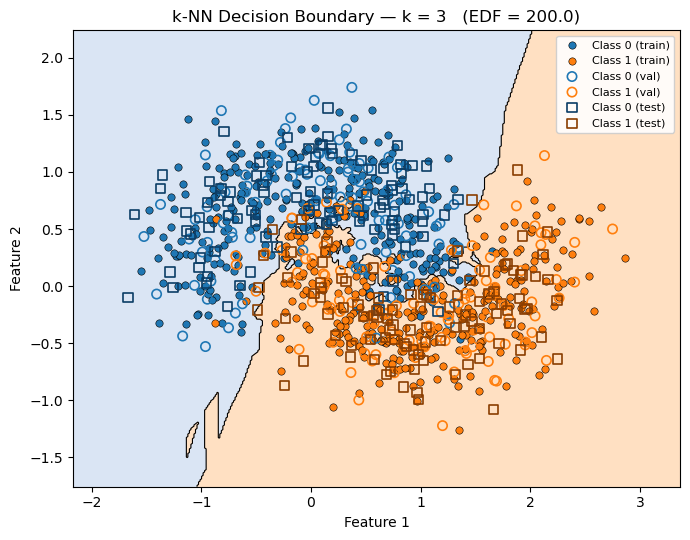

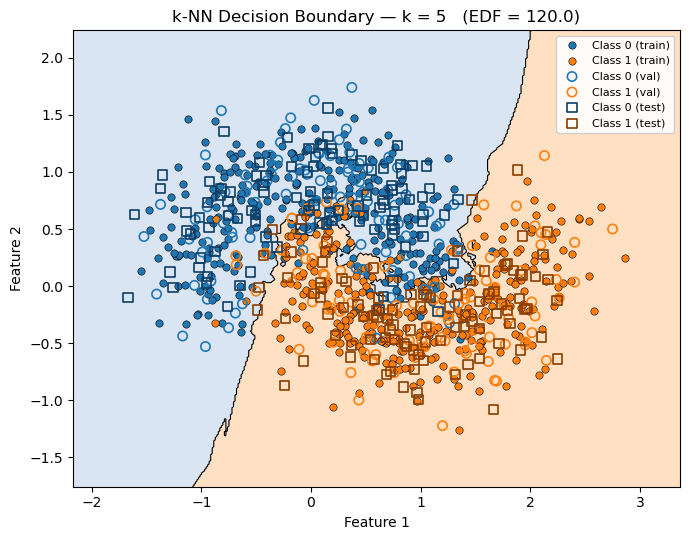

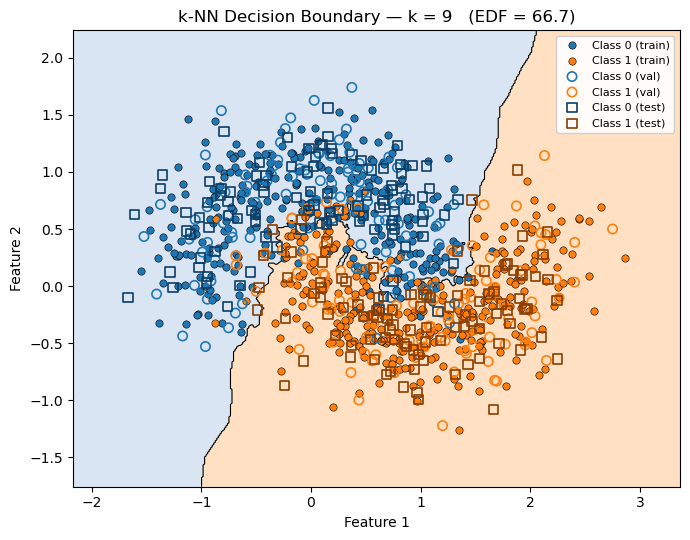

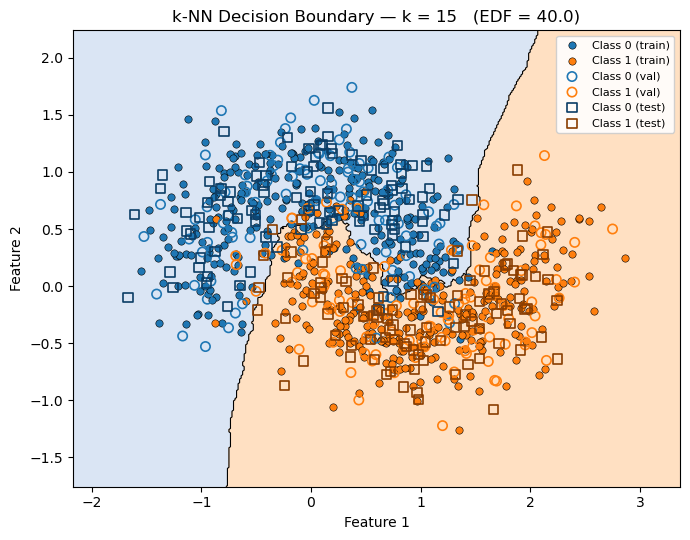

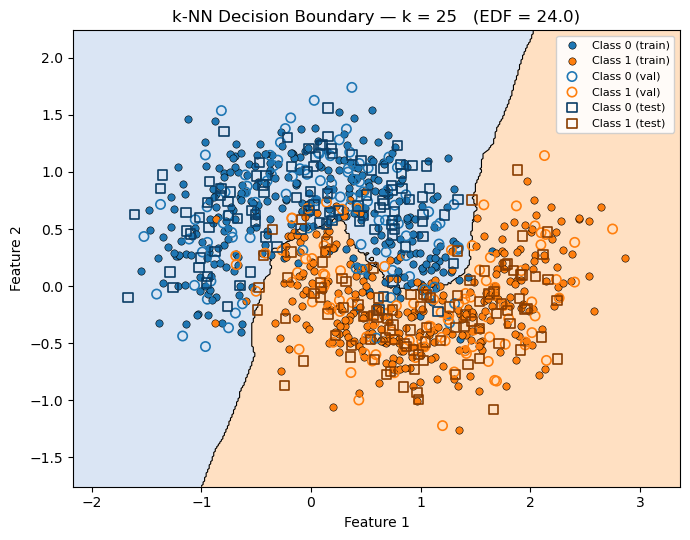

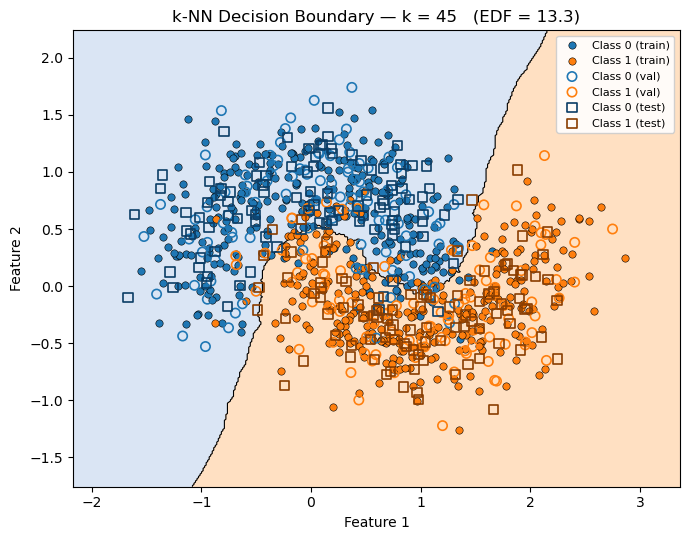

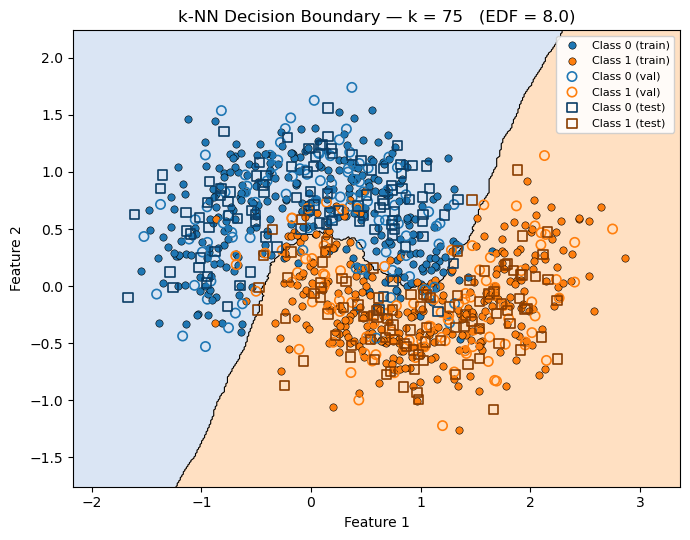

/var/folders/k1/8851q1nj2j3dnxw7hpy7f4f80000gn/T/ipykernel_10903/248989172.py:227: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-s" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(edf_s, test_err_s, "-s", lw=2.0, color="tab:green",


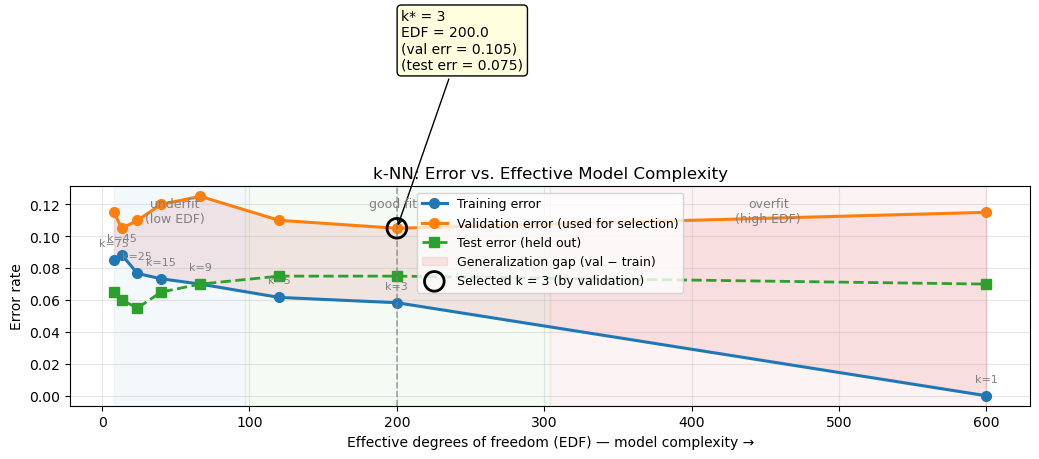

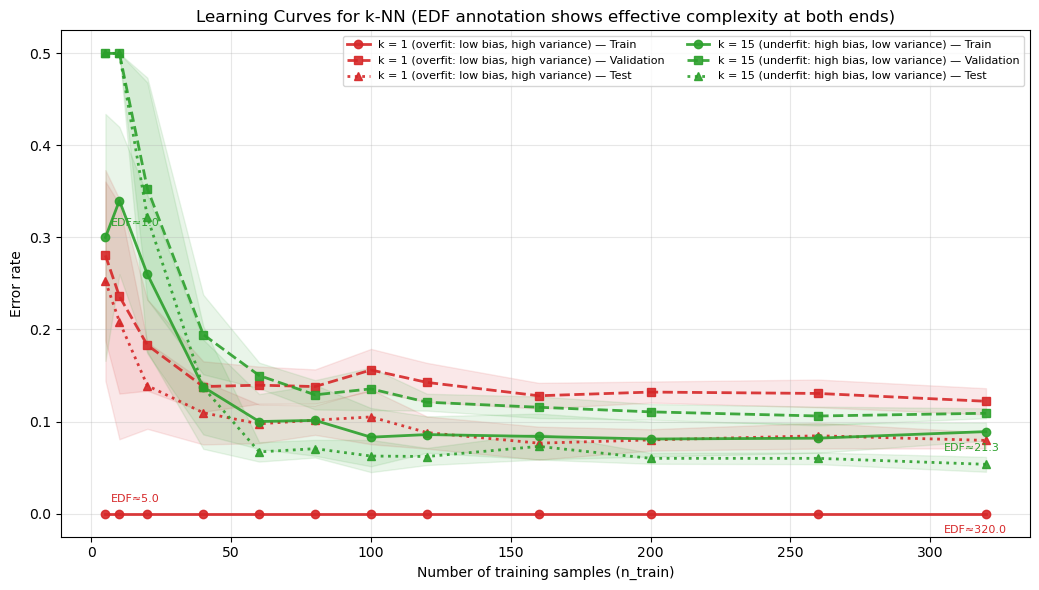


k-NN Classification — Model Complexity Report (EDF axis)
  Total dataset      : 1000
  Training size      : 600
  Validation size    : 200  (used to select k)
  Test size          : 200   (held out; reported once)
  Two-moons noise    : 0.3
  EDF definition     : EDF(k) = n_train / k  (trace of the k-NN hat matrix)

    k |     EDF |  Train Err |   Val Err |  Test Err |  Val Gap
---------------------------------------------------------------
   75 |     8.0 |     0.0850 |    0.1150 |    0.0650 |   0.0300
   45 |    13.3 |     0.0883 |    0.1050 |    0.0600 |   0.0167
   25 |    24.0 |     0.0767 |    0.1100 |    0.0550 |   0.0333
   15 |    40.0 |     0.0733 |    0.1200 |    0.0650 |   0.0467
    9 |    66.7 |     0.0700 |    0.1250 |    0.0700 |   0.0550
    5 |   120.0 |     0.0617 |    0.1100 |    0.0750 |   0.0483
    3 |   200.0 |     0.0583 |    0.1050 |    0.0750 |   0.0467
    1 |   600.0 |     0.0000 |    0.1150 |    0.0700 |   0.1150

----------------------------------------

In [2]:
# =============================================================================
# MODEL COMPLEXITY AND K-NEAREST NEIGHBORS CLASSIFICATION
# =============================================================================
#
# Demonstrates underfitting, appropriate fitting, and overfitting on a
# two-moons classification problem using k-NN with varying k.
#
# COMPLEXITY AXIS: instead of plotting against raw k (which runs *down*
# as complexity goes *up* and is log-scaled), we plot against an
# "effective model complexity" defined as the effective degrees of
# freedom (EDF) of the k-NN classifier:
#
#     EDF(k) = trace( H_k )   where H_k is the k-NN smoothing ("hat")
#                              matrix, H_{ij} = 1/k if x_j is among the
#                              k nearest neighbors of x_i, else 0.
#
# Properties:
#   * k = 1       -> EDF ≈ n  (can fit every training point: max complexity)
#   * k → n       -> EDF → 1  (predicts the global majority: min complexity)
#   * Monotone decreasing in k, smooth, and on a linear scale.
#
# So on an EDF axis the shape matches the polynomial-regression example:
#   low EDF  -> underfit (high bias)
#   mid EDF  -> good fit
#   high EDF -> overfit  (high variance)
#
# Data split (three-way, stratified):
#   * TRAIN       -> fit the model
#   * VALIDATION  -> select k
#   * TEST        -> final unbiased estimate of generalization error
#
# Figures produced:
#   1. Decision-boundary plots for k = 1, 3, 5, 9, 15, 25, 45, 75
#   2. Train / validation / test error vs. EDF   <-- complexity axis
#   3. Learning curves: error vs. n_train, for an overfit and an underfit k
#
# Requirements: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.spatial import cKDTree

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# =============================================================================
# 1. REPRODUCIBILITY
# =============================================================================
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

N_TOTAL = 1000
NOISE = 0.30
VAL_FRACTION = 0.20
TEST_FRACTION = 0.20

K_VALUES = [1, 3, 5, 9, 15, 25, 45, 75]
LEARNING_KS = [1, 15]


# =============================================================================
# 2. DATA  (three-way stratified split)
# =============================================================================
X, y = make_moons(n_samples=N_TOTAL, noise=NOISE, random_state=RANDOM_SEED)

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=TEST_FRACTION, random_state=RANDOM_SEED, stratify=y
)
val_frac_of_tmp = VAL_FRACTION / (1.0 - TEST_FRACTION)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=val_frac_of_tmp,
    random_state=RANDOM_SEED, stratify=y_tmp
)

print(f"Split sizes -> train={len(X_train)}, "
      f"val={len(X_val)}, test={len(X_test)}")

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400),
)
grid = np.c_[xx.ravel(), yy.ravel()]

cmap_bg = ListedColormap(["#aec7e8", "#ffbb78"])


# =============================================================================
# 3. EFFECTIVE DEGREES OF FREEDOM FOR k-NN
# =============================================================================
def knn_edf(k, X_fit):
    """Effective degrees of freedom of k-NN with neighbor count k,
    computed on the given fitting set X_fit.

    H_ii = (number of times point i is its own neighbor) / k
         = 1/k  if x_i is one of its own k nearest neighbors (always true), 
           so actually H_ii = 1/k always for k-NN including self.
    In a k-NN with self included, every point is its own neighbor,
    so H_ii = 1/k for all i. Therefore:

        EDF = trace(H) = n / k

    which is the canonical closed form. We clamp at n (k = 1) and at 1.

    (If you used a k-NN without self-matching, the diagonal would be
     (c_i)/k where c_i counts how many times i is in its own neighbor
     list -- still computable with a KD-tree. We use the closed form
     here because it is exact and cheap.)
    """
    n = len(X_fit)
    return n / float(k)


# =============================================================================
# 4. FIT AND EVALUATE k-NN FOR A GIVEN k
# =============================================================================
def fit_knn(k):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    val_acc = accuracy_score(y_val, model.predict(X_val))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    return model, train_acc, val_acc, test_acc


# =============================================================================
# 5. DECISION-BOUNDARY PLOT FOR ONE k
# =============================================================================
def plot_decision_boundary(k, model, edf):
    Z = model.predict(grid).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.contourf(xx, yy, Z, alpha=0.45, cmap=cmap_bg, levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, Z, colors="k", linewidths=0.8, levels=[0.5])

    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
               s=28, c="#1f77b4", edgecolor="k", linewidth=0.4,
               label="Class 0 (train)", zorder=3)
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
               s=28, c="#ff7f0e", edgecolor="k", linewidth=0.4,
               label="Class 1 (train)", zorder=3)

    ax.scatter(X_val[y_val == 0, 0], X_val[y_val == 0, 1],
               s=45, facecolor="none", edgecolor="#1f77b4",
               linewidth=1.2, label="Class 0 (val)", zorder=4)
    ax.scatter(X_val[y_val == 1, 0], X_val[y_val == 1, 1],
               s=45, facecolor="none", edgecolor="#ff7f0e",
               linewidth=1.2, label="Class 1 (val)", zorder=4)

    ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1],
               s=45, marker="s", facecolor="none", edgecolor="#0b3d66",
               linewidth=1.2, label="Class 0 (test)", zorder=4)
    ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
               s=45, marker="s", facecolor="none", edgecolor="#8a3d00",
               linewidth=1.2, label="Class 1 (test)", zorder=4)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title(f"k-NN Decision Boundary — k = {k}   (EDF = {edf:.1f})")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    plt.tight_layout()
    plt.savefig(f"knn_decision_boundary_k{k:02d}.png", dpi=120)
    plt.show()


# =============================================================================
# 6. FIT ALL K VALUES AND PLOT DECISION BOUNDARIES
# =============================================================================
def fit_all_ks(ks):
    results = {}
    for k in ks:
        model, train_acc, val_acc, test_acc = fit_knn(k)
        edf = knn_edf(k, X_train)
        results[k] = {
            "model": model,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "test_acc": test_acc,
            "edf": edf,
        }
        plot_decision_boundary(k, model, edf)
    return results


results = fit_all_ks(K_VALUES)

ks_arr   = np.array(K_VALUES)
edf_arr  = np.array([results[k]["edf"] for k in K_VALUES])
train_err = np.array([1 - results[k]["train_acc"] for k in K_VALUES])
val_err   = np.array([1 - results[k]["val_acc"] for k in K_VALUES])
test_err  = np.array([1 - results[k]["test_acc"] for k in K_VALUES])


# =============================================================================
# 7. COMPLEXITY CURVE: ERROR vs. EDF  (train / val / test)
# =============================================================================
def plot_error_vs_edf(edf, ks, train_err, val_err, test_err, best_k=None):
    edf = np.asarray(edf)
    train_err = np.asarray(train_err)
    val_err   = np.asarray(val_err)
    test_err  = np.asarray(test_err)

    fig, ax = plt.subplots(figsize=(10.5, 6))

    # Sort by EDF (low -> high = underfit -> overfit)
    order = np.argsort(edf)
    edf_s       = edf[order]
    train_err_s = train_err[order]
    val_err_s   = val_err[order]
    test_err_s  = test_err[order]
    ks_s        = np.asarray(ks)[order]

    ax.plot(edf_s, train_err_s, "-o", lw=2.2, color="tab:blue",
            markersize=7, label="Training error")
    ax.plot(edf_s, val_err_s, "-o", lw=2.2, color="tab:orange",
            markersize=7, label="Validation error (used for selection)")
    ax.plot(edf_s, test_err_s, "-s", lw=2.0, color="tab:green",
            markersize=7, linestyle="--",
            label="Test error (held out)")

    ax.fill_between(edf_s, train_err_s, val_err_s,
                    where=(val_err_s >= train_err_s),
                    color="tab:red", alpha=0.10,
                    label="Generalization gap (val − train)")

    # Annotate each point with its k so the reader can map back
    for xval, tr, k in zip(edf_s, train_err_s, ks_s):
        ax.annotate(f"k={k}", xy=(xval, tr),
                    xytext=(0, 10), textcoords="offset points",
                    fontsize=8, color="gray", ha="center")

    # Highlight the validation-selected model
    if best_k is not None:
        best_i = int(np.where(ks_arr == best_k)[0][0])
        bx = edf[best_i]
        by = val_err[best_i]
        ax.axvline(bx, color="gray", lw=1.2, linestyle="--", alpha=0.7)
        ax.scatter([bx], [by], s=200, facecolor="none",
                   edgecolor="black", linewidth=2, zorder=5,
                   label=f"Selected k = {best_k} (by validation)")
        ax.annotate(f"k* = {best_k}\nEDF = {bx:.1f}\n"
                    f"(val err = {by:.3f})\n(test err = {test_err[best_i]:.3f})",
                    xy=(bx, by),
                    xytext=(bx + 3, by + 0.10),
                    fontsize=10,
                    arrowprops=dict(arrowstyle="->", color="black", lw=1),
                    bbox=dict(boxstyle="round,pad=0.3",
                              facecolor="lightyellow", edgecolor="black"))

    # Regime hints in EDF space
    lo, hi = edf_s.min(), edf_s.max()
    ax.axvspan(lo, lo + 0.15 * (hi - lo), color="tab:blue",  alpha=0.05)
    ax.axvspan(lo + 0.15 * (hi - lo), lo + 0.5 * (hi - lo),
               color="tab:green", alpha=0.05)
    ax.axvspan(lo + 0.5 * (hi - lo), hi, color="tab:red", alpha=0.05)
    ymax = ax.get_ylim()[1]
    ax.text(lo + 0.07 * (hi - lo), ymax * 0.95,
            "underfit\n(low EDF)", ha="center", va="top",
            fontsize=9, color="gray")
    ax.text(lo + 0.32 * (hi - lo), ymax * 0.95,
            "good fit", ha="center", va="top",
            fontsize=9, color="gray")
    ax.text(lo + 0.75 * (hi - lo), ymax * 0.95,
            "overfit\n(high EDF)", ha="center", va="top",
            fontsize=9, color="gray")

    ax.set_xlabel("Effective degrees of freedom (EDF) — model complexity →")
    ax.set_ylabel("Error rate")
    ax.set_title("k-NN: Error vs. Effective Model Complexity")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper center", fontsize=9)
    plt.tight_layout()
    plt.savefig("knn_error_vs_edf.png", dpi=120)
    plt.show()


# =============================================================================
# 8. LEARNING CURVES: ERROR vs. n_train  (for overfit and underfit k)
# =============================================================================
def learning_curve_for_k(k, n_train_sizes, n_repeats=10):
    avg_train_err, avg_val_err, avg_test_err = [], [], []
    std_train_err, std_val_err, std_test_err = [], [], []
    edf_list = []

    for n in n_train_sizes:
        train_errors, val_errors, test_errors = [], [], []
        edfs = []
        for _ in range(n_repeats):
            idx = rng.choice(len(X_train), size=n, replace=False)
            Xs, ys = X_train[idx], y_train[idx]

            kk = min(k, n)
            model = KNeighborsClassifier(n_neighbors=kk)
            model.fit(Xs, ys)

            train_errors.append(1 - accuracy_score(ys, model.predict(Xs)))
            val_errors.append(1 - accuracy_score(y_val, model.predict(X_val)))
            test_errors.append(1 - accuracy_score(y_test, model.predict(X_test)))
            edfs.append(knn_edf(kk, Xs))

        avg_train_err.append(np.mean(train_errors))
        avg_val_err.append(np.mean(val_errors))
        avg_test_err.append(np.mean(test_errors))
        std_train_err.append(np.std(train_errors))
        std_val_err.append(np.std(val_errors))
        std_test_err.append(np.std(test_errors))
        edf_list.append(np.mean(edfs))

    return (np.array(avg_train_err), np.array(avg_val_err), np.array(avg_test_err),
            np.array(std_train_err), np.array(std_val_err), np.array(std_test_err),
            np.array(edf_list))


def plot_learning_curves(ks, n_train_sizes):
    fig, ax = plt.subplots(figsize=(10.5, 6))

    base_colors = {ks[0]: "tab:red", ks[1]: "tab:green"}
    labels = {
        ks[0]: f"k = {ks[0]} (overfit: low bias, high variance)",
        ks[1]: f"k = {ks[1]} (underfit: high bias, low variance)",
    }

    for k in ks:
        tr, va, te, tr_s, va_s, te_s, edfs = learning_curve_for_k(k, n_train_sizes)
        c = base_colors[k]

        ax.plot(n_train_sizes, tr, "-o", lw=2, color=c,
                label=f"{labels[k]} — Train", alpha=0.9)
        ax.fill_between(n_train_sizes, tr - tr_s, tr + tr_s,
                        color=c, alpha=0.10)
        ax.plot(n_train_sizes, va, "--s", lw=2, color=c,
                label=f"{labels[k]} — Validation", alpha=0.9)
        ax.fill_between(n_train_sizes, va - va_s, va + va_s,
                        color=c, alpha=0.10)
        ax.plot(n_train_sizes, te, ":^", lw=2, color=c,
                label=f"{labels[k]} — Test", alpha=0.9)
        ax.fill_between(n_train_sizes, te - te_s, te + te_s,
                        color=c, alpha=0.10)

        # Annotate EDF at the two ends so the reader knows how EDF varies
        ax.annotate(f"EDF≈{edfs[0]:.1f}", xy=(n_train_sizes[0], tr[0]),
                    xytext=(4, 8), textcoords="offset points",
                    fontsize=8, color=c)
        ax.annotate(f"EDF≈{edfs[-1]:.1f}", xy=(n_train_sizes[-1], tr[-1]),
                    xytext=(-30, -14), textcoords="offset points",
                    fontsize=8, color=c)

    ax.set_xlabel("Number of training samples (n_train)")
    ax.set_ylabel("Error rate")
    ax.set_title("Learning Curves for k-NN "
                 "(EDF annotation shows effective complexity at both ends)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig("knn_learning_curves.png", dpi=120)
    plt.show()


# =============================================================================
# 9. REPORTING
# =============================================================================
def print_table(ks, edf, train_err, val_err, test_err):
    header = (f"{'k':>5} | {'EDF':>7} | {'Train Err':>10} | "
              f"{'Val Err':>9} | {'Test Err':>9} | {'Val Gap':>8}")
    print(header)
    print("-" * len(header))
    order = np.argsort(edf)
    for i in order:
        print(f"{ks[i]:>5d} | {edf[i]:>7.1f} | {train_err[i]:>10.4f} | "
              f"{val_err[i]:>9.4f} | {test_err[i]:>9.4f} | "
              f"{val_err[i] - train_err[i]:>8.4f}")


def select_best_k(ks, val_err):
    ks = np.asarray(ks)
    return int(ks[int(np.argmin(val_err))])


# =============================================================================
# 10. MAIN
# =============================================================================
def main():
    best_k = select_best_k(K_VALUES, val_err)
    best_i = int(np.where(ks_arr == best_k)[0][0])

    # ---- Complexity curve on EDF axis ----
    plot_error_vs_edf(edf_arr, ks_arr, train_err, val_err, test_err,
                      best_k=best_k)

    # ---- Learning curves ----
    n_train_sizes = [5, 10, 20, 40, 60, 80, 100, 120, 160, 200, 260, 320]
    n_train_sizes = [n for n in n_train_sizes if n <= len(X_train)]
    plot_learning_curves(LEARNING_KS, n_train_sizes)

    # ---- Console report ----
    print()
    print("=" * 78)
    print("k-NN Classification — Model Complexity Report (EDF axis)")
    print("=" * 78)
    print(f"  Total dataset      : {N_TOTAL}")
    print(f"  Training size      : {len(X_train)}")
    print(f"  Validation size    : {len(X_val)}  (used to select k)")
    print(f"  Test size          : {len(X_test)}   (held out; reported once)")
    print(f"  Two-moons noise    : {NOISE}")
    print(f"  EDF definition     : EDF(k) = n_train / k  "
          f"(trace of the k-NN hat matrix)")
    print()
    print_table(ks_arr, edf_arr, train_err, val_err, test_err)

    print()
    print("-" * 78)
    print("FINAL TEST REPORT — selected by validation, evaluated on test")
    print("-" * 78)
    print(f"  Selected k (lowest validation error) : {best_k}")
    print(f"  EDF of selected model                : {edf_arr[best_i]:.1f}")
    print(f"  Training error of selected model     : {train_err[best_i]:.4f}")
    print(f"  Validation error of selected model   : {val_err[best_i]:.4f}")
    print(f"  TEST error of selected model         : {test_err[best_i]:.4f}")
    print(f"  |Val − Test| error difference        : "
          f"{abs(val_err[best_i] - test_err[best_i]):.4f}")

    print()
    print("Educational interpretation:")
    print("  * The x-axis is now effective degrees of freedom (EDF = n/k),")
    print("    so complexity increases to the RIGHT — same convention as")
    print("    polynomial degree in the regression example.")
    print("  * Low  EDF (large k) -> underfit (high bias, low variance).")
    print("  * High EDF (small k) -> overfit  (low bias, high variance).")
    print("  * Validation chooses k; test error is reported once.")
    print("  * In the learning curves, EDF is annotated at both ends to")
    print("    show how the effective complexity of a *fixed-k* model")
    print("    changes with sample size (for k=1 it grows with n; for")
    print("    k=15 it stays roughly constant until n < 15).")


if __name__ == "__main__":
    main()


Descomposición integrada:  MSE  vs.  Bias^2 + Var + Noise
  d |    Bias^2 |       Var |   Noise |      Suma |       MSE |      diff
------------------------------------------------------------------------
  0 |    0.5000 |    0.0234 |  0.0625 |    0.5859 |    0.5859 |  1.11e-16
  1 |    0.1964 |    0.0256 |  0.0625 |    0.2845 |    0.2845 |  1.11e-16
  2 |    0.1989 |    0.0674 |  0.0625 |    0.3288 |    0.3288 |  5.55e-17
  3 |    0.0046 |    0.0158 |  0.0625 |    0.0829 |    0.0829 |  1.39e-17
  4 |    0.0059 |    0.0356 |  0.0625 |    0.1040 |    0.1040 |  1.39e-17
  5 |    0.0000 |    0.0558 |  0.0625 |    0.1183 |    0.1183 |  0.00e+00
  6 |    0.0007 |    0.5718 |  0.0625 |    0.6350 |    0.6350 |  1.11e-16
  7 |    0.0083 |    2.5082 |  0.0625 |    2.5790 |    2.5790 |  4.44e-16
  8 |    0.0510 |   11.5678 |  0.0625 |   11.6813 |   11.6813 |  3.55e-15
  9 |    0.9928 |  198.6110 |  0.0625 |  199.6663 |  199.6663 |  0.00e+00
 10 |    0.4039 | 2798.7317 |  0.0625 | 2799.1981 | 27

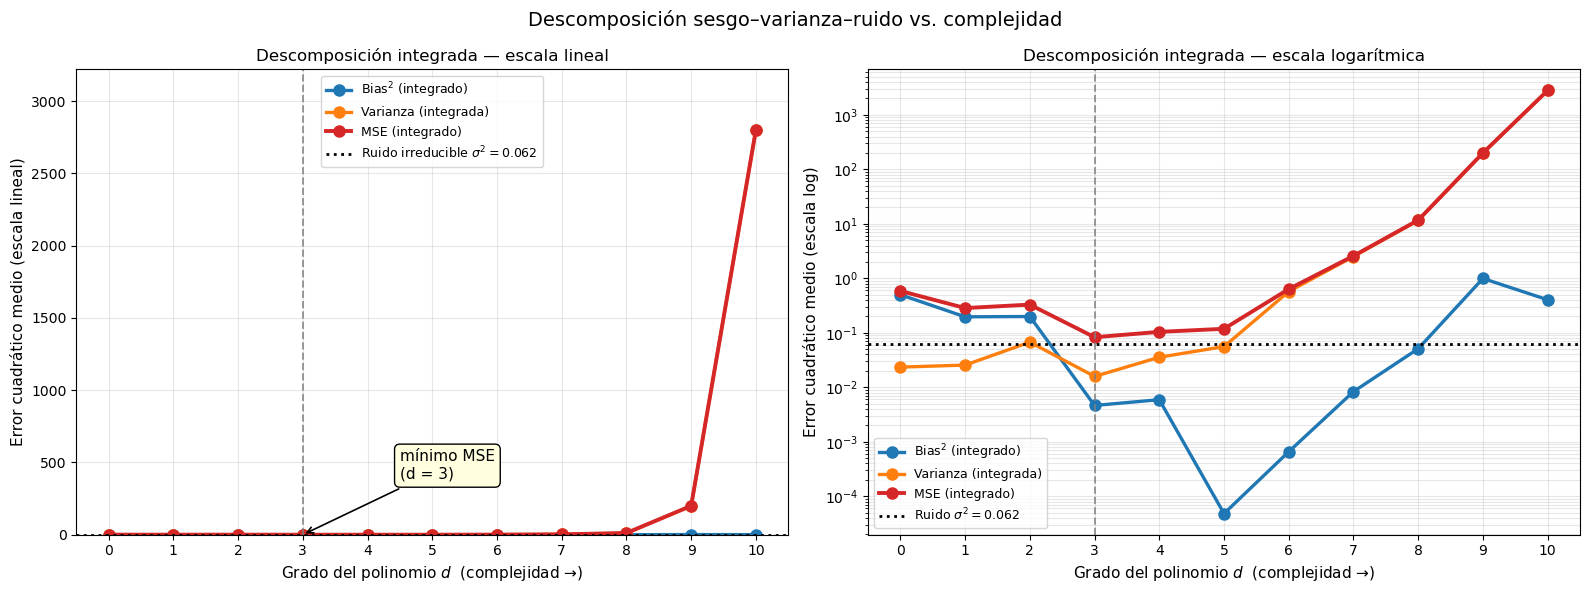

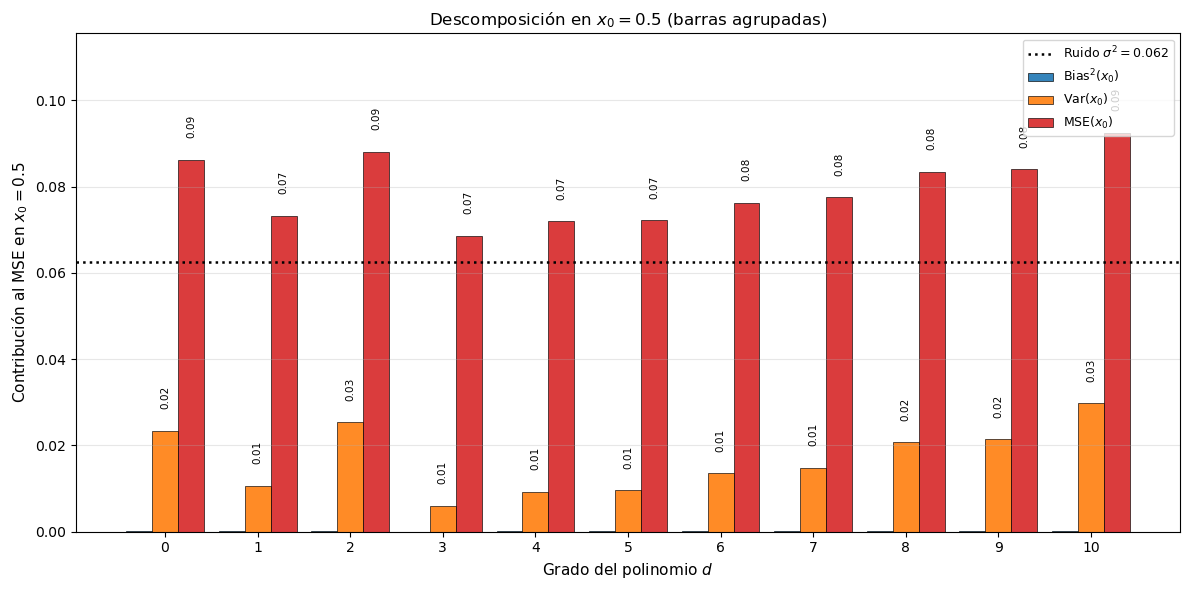

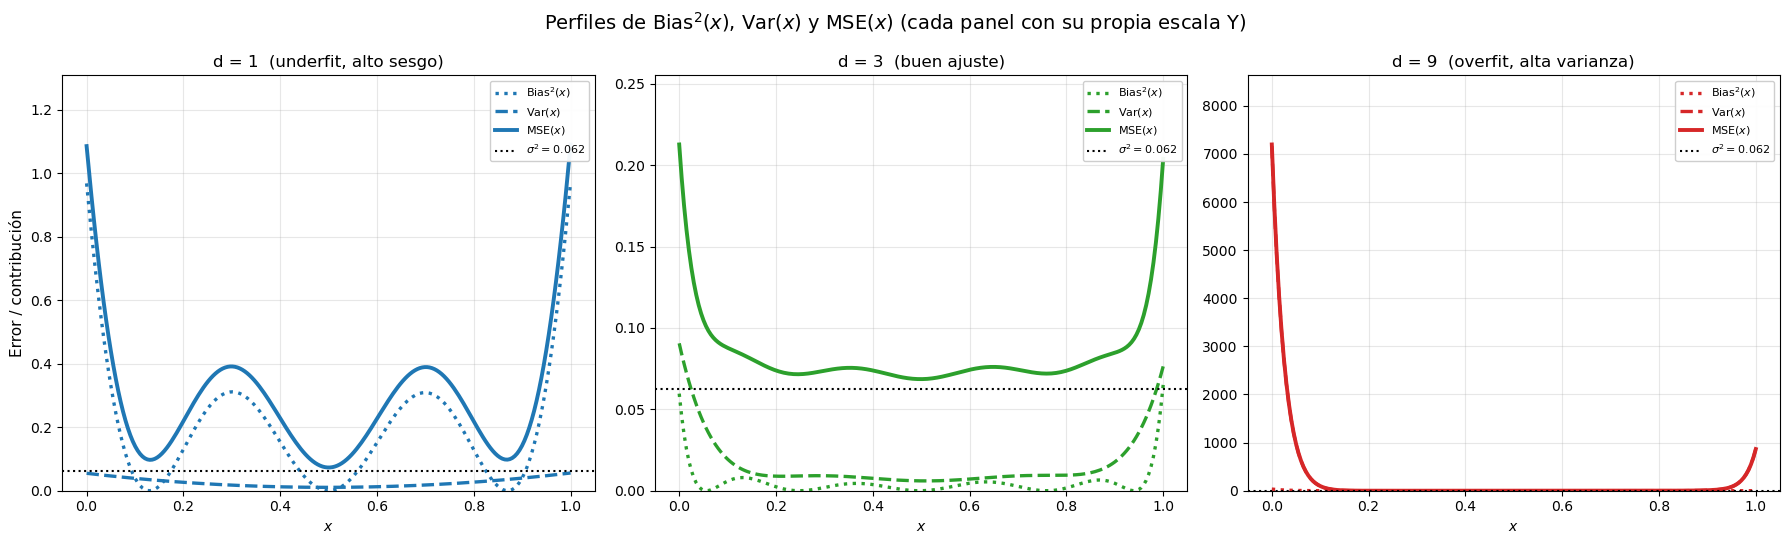

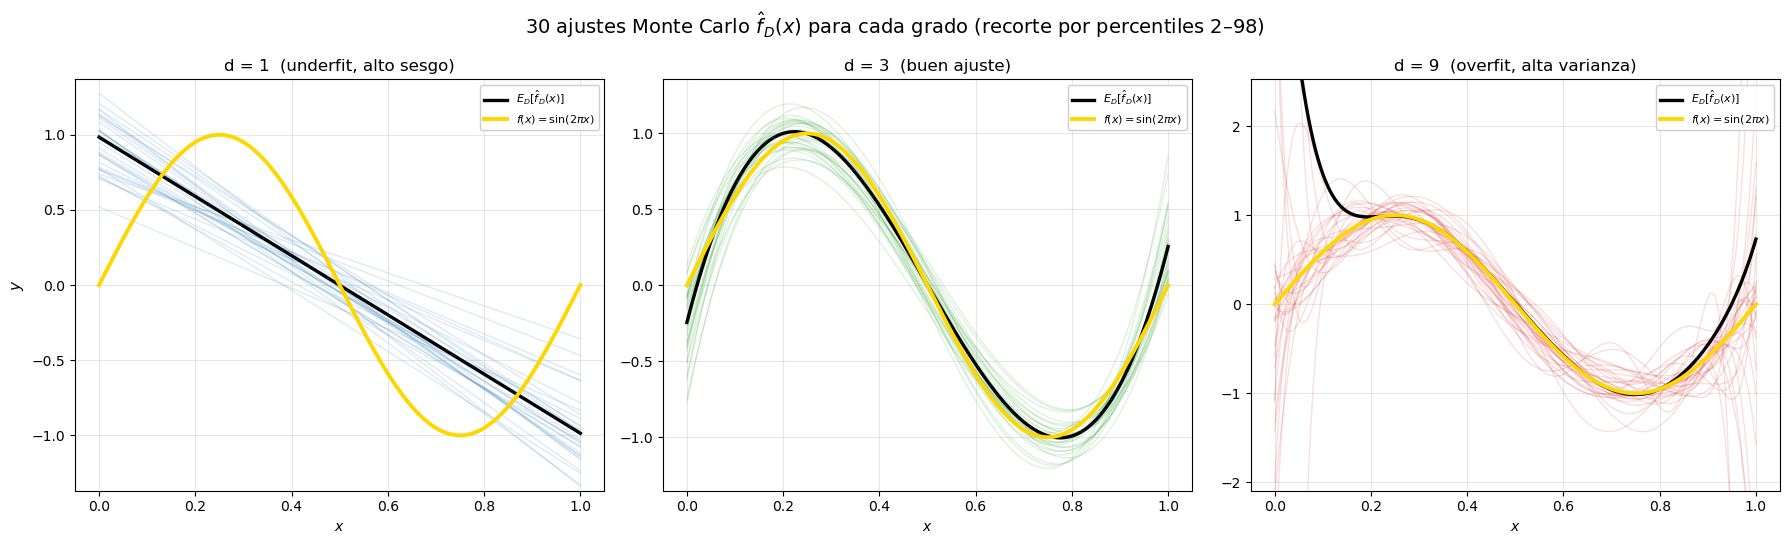


Resumen:
  Grado con menor MSE integrado : 3
  Bias^2 en ese grado           : 0.0046
  Varianza en ese grado         : 0.0158
  Ruido irreducible (sigma^2)   : 0.0625
  MSE = Bias^2 + Var + Noise    : 0.0829

Interpretación:
  * d bajo  -> Bias^2 alto, Var baja  -> UNDERFIT (infraajuste).
  * d medio -> compromiso óptimo      -> GOOD FIT.
  * d alto  -> Bias^2 bajo, Var alta  -> OVERFIT (sobreajuste).
  * El ruido irreducible sigma^2 nunca desaparece.


In [4]:
# =============================================================================
# SESGO–VARIANZA–RUIDO EN LA REGRESIÓN DE UNA SINUSOIDE RUIDOSA
# =============================================================================
# Modelo de datos:
#     y = sin(2*pi*x) + eps,   eps ~ N(0, sigma^2),   x ~ U[0,1]
#
# Para cada grado polinómico d = 0..10:
#   * M conjuntos de entrenamiento independientes (Monte Carlo).
#   * Se estima Bias^2(x), Var(x), MSE(x) en una rejilla de x.
#   * Se verifica numéricamente que  MSE ≈ Bias^2 + Var + Noise.
#
# Descomposición (ecuaciones en LaTeX):
#
#   E_{D,y}[(y - f_hat_D(x))^2]
#       = ( E_D[f_hat_D(x)] - f(x) )^2          <- Bias^2(x)
#       + E_D[ (f_hat_D(x) - E_D[f_hat_D(x)])^2 ]  <- Var(x)
#       + sigma^2                                 <- Ruido irreducible
#
#   E[MSE] = ∫ [ Bias^2(x) + Var(x) ] p(x) dx + sigma^2
#
# Figuras (con mejoras de escala):
#   1. Descomposición integrada — doble panel: escala lineal + log.
#   2. Descomposición en un punto x0 — barras agrupadas con etiquetas.
#   3. Perfiles Bias^2(x), Var(x), MSE(x) para d ∈ {1, 3, 9},
#      cada panel con su propia escala Y.
#   4. Curvas Monte Carlo f_hat_D(x) para d ∈ {1, 3, 9}, recortadas
#      por percentiles 2–98 para que los outliers no aplasten el dibujo.
#
# Requiere: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures


# ---------------------------------------------------------------------------
# 1. Parámetros
# ---------------------------------------------------------------------------
RANDOM_SEED = 0
rng = np.random.default_rng(RANDOM_SEED)

N_TRAIN = 25           # tamaño del conjunto de entrenamiento
SIGMA   = 0.25         # desviación típica del ruido
M       = 500          # nº de conjuntos de entrenamiento por grado
DEGREES = list(range(0, 11))
X_PLOT  = np.linspace(0.0, 1.0, 200).reshape(-1, 1)


def true_function(x):
    return np.sin(2 * np.pi * x.ravel())


# ---------------------------------------------------------------------------
# 2. Pipeline polinómico
# ---------------------------------------------------------------------------
def make_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=True)),
        ("lin",  LinearRegression(fit_intercept=False)),
    ])


# ---------------------------------------------------------------------------
# 3. Experimento Monte Carlo
# ---------------------------------------------------------------------------
f_hat_all = {d: np.zeros((M, X_PLOT.shape[0])) for d in DEGREES}

for m in range(M):
    x_tr = rng.uniform(0.0, 1.0, size=N_TRAIN)
    y_tr = true_function(x_tr) + rng.normal(0.0, SIGMA, size=N_TRAIN)
    X_tr = x_tr.reshape(-1, 1)

    for d in DEGREES:
        model = make_model(d)
        model.fit(X_tr, y_tr)
        f_hat_all[d][m, :] = model.predict(X_PLOT)


# ---------------------------------------------------------------------------
# 4. Descomposición en la rejilla
# ---------------------------------------------------------------------------
f_true_grid = true_function(X_PLOT)
noise = SIGMA ** 2

bias2_grid, var_grid, mse_grid = {}, {}, {}

for d in DEGREES:
    f_hat = f_hat_all[d]
    mean_pred = f_hat.mean(axis=0)
    bias2_grid[d] = (mean_pred - f_true_grid) ** 2
    var_grid[d]   = ((f_hat - mean_pred) ** 2).mean(axis=0)
    mse_grid[d]   = ((f_true_grid - f_hat) ** 2).mean(axis=0) + noise


def integrate_over_x(f_grid):
    return np.trapz(f_grid, X_PLOT.ravel())


bias2_int = np.array([integrate_over_x(bias2_grid[d]) for d in DEGREES])
var_int   = np.array([integrate_over_x(var_grid[d])   for d in DEGREES])
mse_int   = np.array([integrate_over_x(mse_grid[d])   for d in DEGREES])
total     = bias2_int + var_int + noise


# ---------------------------------------------------------------------------
# 5. Verificación numérica
# ---------------------------------------------------------------------------
print("\nDescomposición integrada:  MSE  vs.  Bias^2 + Var + Noise")
print(f"{'d':>3} | {'Bias^2':>9} | {'Var':>9} | {'Noise':>7} | "
      f"{'Suma':>9} | {'MSE':>9} | {'diff':>9}")
print("-" * 72)
for i, d in enumerate(DEGREES):
    print(f"{d:>3} | {bias2_int[i]:>9.4f} | {var_int[i]:>9.4f} | "
          f"{noise:>7.4f} | {total[i]:>9.4f} | {mse_int[i]:>9.4f} | "
          f"{abs(mse_int[i] - total[i]):>9.2e}")


# ---------------------------------------------------------------------------
# 6. Figura 1 — Descomposición integrada (doble panel: lineal + log)
# ---------------------------------------------------------------------------
best_d = DEGREES[int(np.argmin(mse_int))]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel izquierdo: escala lineal, eje Y recortado
ax = axes[0]
ax.plot(DEGREES, bias2_int, "-o", lw=2.4, color="tab:blue",
        markersize=8, label=r"Bias$^2$ (integrado)")
ax.plot(DEGREES, var_int, "-o", lw=2.4, color="tab:orange",
        markersize=8, label="Varianza (integrada)")
ax.plot(DEGREES, mse_int, "-o", lw=2.8, color="tab:red",
        markersize=8, label="MSE (integrado)")
ax.axhline(noise, color="k", linestyle=":", lw=2,
           label=rf"Ruido irreducible $\sigma^2={noise:.3f}$")

ymax = max(mse_int.max(), var_int.max(), bias2_int.max()) * 1.15
ax.set_ylim(0, ymax)

ax.axvline(best_d, color="gray", lw=1.4, linestyle="--", alpha=0.8)
ax.annotate(f"mínimo MSE\n(d = {best_d})",
            xy=(best_d, mse_int[best_d]),
            xytext=(best_d + 1.5, mse_int[best_d] + 0.12 * ymax),
            fontsize=11,
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
            bbox=dict(boxstyle="round,pad=0.35",
                      facecolor="lightyellow", edgecolor="black"))

ax.set_xlabel("Grado del polinomio $d$  (complejidad →)", fontsize=11)
ax.set_ylabel("Error cuadrático medio (escala lineal)", fontsize=11)
ax.set_title("Descomposición integrada — escala lineal", fontsize=12)
ax.set_xticks(DEGREES)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper center", fontsize=9)

# Panel derecho: escala log para ver todo
ax = axes[1]
eps = 1e-6
ax.semilogy(DEGREES, bias2_int + eps, "-o", lw=2.4, color="tab:blue",
            markersize=8, label=r"Bias$^2$ (integrado)")
ax.semilogy(DEGREES, var_int + eps, "-o", lw=2.4, color="tab:orange",
            markersize=8, label="Varianza (integrada)")
ax.semilogy(DEGREES, mse_int + eps, "-o", lw=2.8, color="tab:red",
            markersize=8, label="MSE (integrado)")
ax.axhline(noise, color="k", linestyle=":", lw=2,
           label=rf"Ruido $\sigma^2={noise:.3f}$")

ax.axvline(best_d, color="gray", lw=1.4, linestyle="--", alpha=0.8)
ax.set_xlabel("Grado del polinomio $d$  (complejidad →)", fontsize=11)
ax.set_ylabel("Error cuadrático medio (escala log)", fontsize=11)
ax.set_title("Descomposición integrada — escala logarítmica", fontsize=12)
ax.set_xticks(DEGREES)
ax.grid(True, alpha=0.3, which="both")
ax.legend(loc="lower left", fontsize=9)

fig.suptitle("Descomposición sesgo–varianza–ruido vs. complejidad",
             fontsize=14)
plt.tight_layout()
plt.savefig("bias_variance_integrated.png", dpi=150)
plt.show()


# ---------------------------------------------------------------------------
# 7. Figura 2 — Descomposición en x0 (barras agrupadas con etiquetas)
# ---------------------------------------------------------------------------
x0 = 0.5
idx0 = int(np.argmin(np.abs(X_PLOT.ravel() - x0)))
bias2_x0 = np.array([bias2_grid[d][idx0] for d in DEGREES])
var_x0   = np.array([var_grid[d][idx0]   for d in DEGREES])
mse_x0   = np.array([mse_grid[d][idx0]   for d in DEGREES])

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.28
xs = np.array(DEGREES)

bars_b = ax.bar(xs - width, bias2_x0, width=width, color="tab:blue",
                alpha=0.9, label=r"Bias$^2(x_0)$", edgecolor="k",
                linewidth=0.5)
bars_v = ax.bar(xs,         var_x0,   width=width, color="tab:orange",
                alpha=0.9, label=r"Var$(x_0)$", edgecolor="k",
                linewidth=0.5)
bars_n = ax.bar(xs + width, mse_x0,   width=width, color="tab:red",
                alpha=0.9, label=r"MSE$(x_0)$", edgecolor="k",
                linewidth=0.5)

ax.axhline(noise, color="k", linestyle=":", lw=1.8,
           label=rf"Ruido $\sigma^2={noise:.3f}$")


def annotate_bars(bars, values, threshold=0.005):
    for bar, v in zip(bars, values):
        if v > threshold:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.005,
                    f"{v:.2f}", ha="center", va="bottom",
                    fontsize=7.5, color="black", rotation=90)


annotate_bars(bars_b, bias2_x0)
annotate_bars(bars_v, var_x0)
annotate_bars(bars_n, mse_x0)

ymax = max(bias2_x0.max(), var_x0.max(), mse_x0.max()) * 1.25
ax.set_ylim(0, ymax)

ax.set_xticks(DEGREES)
ax.set_xlabel("Grado del polinomio $d$", fontsize=11)
ax.set_ylabel(rf"Contribución al MSE en $x_0={x0}$", fontsize=11)
ax.set_title(rf"Descomposición en $x_0={x0}$ (barras agrupadas)",
             fontsize=12)
ax.grid(True, alpha=0.3, axis="y")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("bias_variance_point.png", dpi=150)
plt.show()


# ---------------------------------------------------------------------------
# 8. Figura 3 — Perfiles Bias^2(x), Var(x), MSE(x) (sin sharey)
# ---------------------------------------------------------------------------
example_degrees = [1, 3, 9]
colors = {1: "tab:blue", 3: "tab:green", 9: "tab:red"}
titles = {1: "d = 1  (underfit, alto sesgo)",
          3: "d = 3  (buen ajuste)",
          9: "d = 9  (overfit, alta varianza)"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, d in zip(axes, example_degrees):
    c = colors[d]
    ax.plot(X_PLOT, bias2_grid[d], lw=2.4, color=c,
            linestyle=":", label=r"Bias$^2(x)$")
    ax.plot(X_PLOT, var_grid[d], lw=2.4, color=c,
            linestyle="--", label="Var$(x)$")
    ax.plot(X_PLOT, mse_grid[d], lw=2.8, color=c,
            linestyle="-", label="MSE$(x)$")
    ax.axhline(noise, color="k", linestyle=":", lw=1.5,
               label=rf"$\sigma^2={noise:.3f}$")

    panel_max = max(bias2_grid[d].max(),
                    var_grid[d].max(),
                    mse_grid[d].max())
    ax.set_ylim(0, panel_max * 1.2)

    ax.set_title(titles[d], fontsize=12)
    ax.set_xlabel("$x$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper right", framealpha=0.95)

axes[0].set_ylabel("Error / contribución", fontsize=11)
fig.suptitle(r"Perfiles de Bias$^2(x)$, Var$(x)$ y MSE$(x)$ "
             r"(cada panel con su propia escala Y)", fontsize=14)
plt.tight_layout()
plt.savefig("bias_variance_profiles.png", dpi=150)
plt.show()


# ---------------------------------------------------------------------------
# 9. Figura 4 — Curvas Monte Carlo (recortadas por percentiles 2–98)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, d in zip(axes, example_degrees):
    c = colors[d]
    f_hat = f_hat_all[d]

    for m in range(30):
        ax.plot(X_PLOT, f_hat[m], color=c, alpha=0.15, lw=1)

    ax.plot(X_PLOT, f_hat.mean(axis=0), color="black",
            lw=2.4, label=r"$E_D[\hat f_D(x)]$")
    ax.plot(X_PLOT, f_true_grid, color="gold", lw=2.8,
            label=r"$f(x)=\sin(2\pi x)$")

    lo = np.percentile(f_hat, 2)
    hi = np.percentile(f_hat, 98)
    margin = 0.25 * max(abs(lo), abs(hi), 1.0)
    ax.set_ylim(lo - margin, hi + margin)

    ax.set_title(titles[d], fontsize=12)
    ax.set_xlabel("$x$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper right", framealpha=0.95)

axes[0].set_ylabel("$y$", fontsize=11)
fig.suptitle(r"30 ajustes Monte Carlo $\hat f_D(x)$ para cada grado "
             r"(recorte por percentiles 2–98)", fontsize=14)
plt.tight_layout()
plt.savefig("bias_variance_mc_curves.png", dpi=150)
plt.show()


# ---------------------------------------------------------------------------
# 10. Resumen
# ---------------------------------------------------------------------------
print("\nResumen:")
print(f"  Grado con menor MSE integrado : {best_d}")
print(f"  Bias^2 en ese grado           : {bias2_int[best_d]:.4f}")
print(f"  Varianza en ese grado         : {var_int[best_d]:.4f}")
print(f"  Ruido irreducible (sigma^2)   : {noise:.4f}")
print(f"  MSE = Bias^2 + Var + Noise    : "
      f"{bias2_int[best_d] + var_int[best_d] + noise:.4f}")
print()
print("Interpretación:")
print("  * d bajo  -> Bias^2 alto, Var baja  -> UNDERFIT (infraajuste).")
print("  * d medio -> compromiso óptimo      -> GOOD FIT.")
print("  * d alto  -> Bias^2 bajo, Var alta  -> OVERFIT (sobreajuste).")
print("  * El ruido irreducible sigma^2 nunca desaparece.")